<!-- CONSIGNES -->
# TP1 — Mise à jour bayésienne et conjugaison Beta-Binomial

**Chapitre 1 — Introduction et fondements bayésiens** — EPD-SDIA-4112 « Statistique Bayésienne », Master 1 SDIA
**Enseignante : Dr. Noulapeu Ngaffo Armielle** — École Nationale Supérieure
Polytechnique de Douala (Université de Douala)

---

## Objectifs

- écrire une vraisemblance, un a priori et en déduire un posterior ;
- vérifier par le calcul que trois voies différentes (conjugaison, grille,
  échantillonnage) donnent la **même** loi a posteriori ;
- comprendre que le posterior d'aujourd'hui est le prior de demain.

## Ce qui est demandé

1. Parcourir les sections 1 à 3 et vérifier les sorties affichées.
2. Compléter les **quatre zones « À vous »** (elles se suivent dans le notebook).
3. Section 4 : refaire l'exercice de synthèse sur le taux de conversion d'un site
   en choisissant vous-même un a priori et en justifiant ce choix en une phrase.

## Barème — 10 points

| Critère | Points |
|---|---|
| Zone « À vous » 1 — posterior analytique | 2 |
| Zone « À vous » 2 — vérification par grille | 2 |
| Zone « À vous » 3 — mise à jour séquentielle | 2 |
| Zone « À vous » 4 — exercice de synthèse | 3 |
| Justification du choix d'a priori (une phrase, argumentée) | 1 |

## Mode d'emploi

- **Noyau Jupyter** : `sdia-bayes` (Python 3.11, PyMC, ArviZ, NumPy, SciPy, Matplotlib).
- Ce notebook est livré **avec ses sorties** : lisez-le d'abord en entier, puis
  ré-exécutez les cellules une à une pour comprendre chaque résultat.
- Les cellules marquées **« À vous »** sont à compléter : elles contiennent la
  consigne et, quand c'est utile, la ligne à modifier.
- Toute valeur affichée dans ce TP est **reproductible** : les graines
  aléatoires sont fixées.
- Rendu : le notebook complété (`.ipynb`), avec vos sorties exécutées.


# TP1 — Mise à jour bayésienne et conjugaison Beta-Binomial

_Cours EPD-SDIA-4112 — Statistique Bayésienne — Master 1 SDIA. Exécutez les cellules dans l'ordre._

## Objectifs

À la fin de ce TP vous saurez :

1. calculer un posterior conjugué **à la main** et le **vérifier par le calcul** ;
2. interpréter un intervalle de crédibilité, et le comparer à un intervalle de confiance ;
3. estimer un posterior par **trois méthodes** (analytique, grille, Monte-Carlo) et mesurer leurs écarts ;
4. suivre une **mise à jour séquentielle** et expliquer pourquoi l'ordre des observations ne change rien.

> Durée : 1 h 30. Rendu : ce notebook exécuté + réponses aux zones « **À vous** ».

In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
RNG = np.random.default_rng(4112)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| scipy", stats.__name__)


numpy 2.4.6 | scipy scipy.stats


---
# 1. Le problème fondateur

On lance 10 fois une pièce et on obtient **7 faces**. On veut la probabilité $\theta$ de tomber sur face.

Modèle : $y \mid \theta \sim \mathrm{Bin}(10,\theta)$ ; prior $\theta \sim \mathrm{Beta}(1,1)$ (uniforme).

**À la main** — posterior conjugué :
$$p(\theta\mid y) \propto \theta^{7}(1-\theta)^{3} \Rightarrow \theta\mid y \sim \mathrm{Beta}(1+7,\;1+3) = \mathrm{Beta}(8,4)$$

In [2]:
a_prior, b_prior = 1, 1
n, k = 10, 7              # 10 lancers, 7 faces

a_post, b_post = a_prior + k, b_prior + n - k
post = stats.beta(a_post, b_post)

print(f"posterior                 : Beta({a_post}, {b_post})")
print(f"moyenne a posteriori      : {post.mean():.4f}")
print(f"mode (MAP)                : {(a_post-1)/(a_post+b_post-2):.4f}")
print(f"ecart-type                : {post.std():.4f}")
print(f"IC 95 % (queues egales)   : [{post.ppf(.025):.4f} ; {post.ppf(.975):.4f}]")
print(f"P(theta > 0.5 | y)        : {1 - post.cdf(.5):.4f}")
print(f"P(theta > 0.7 | y)        : {1 - post.cdf(.7):.4f}")

posterior                 : Beta(8, 4)
moyenne a posteriori      : 0.6667
mode (MAP)                : 0.7000
ecart-type                : 0.1307
IC 95 % (queues egales)   : [0.3903 ; 0.8907]
P(theta > 0.5 | y)        : 0.8867
P(theta > 0.7 | y)        : 0.4304


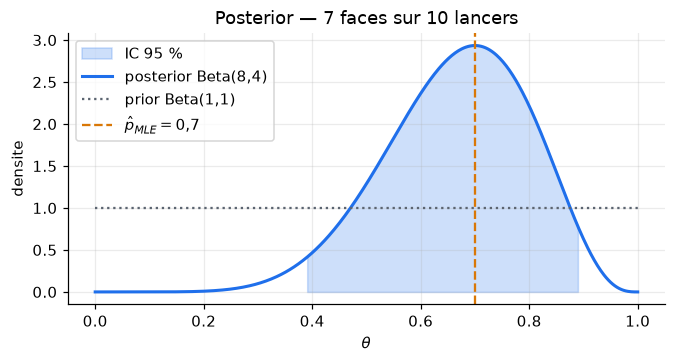

In [3]:
grid = np.linspace(0, 1, 500)
plt.figure(figsize=(7, 3.2))
plt.fill_between(grid, post.pdf(grid), where=(grid >= post.ppf(.025)) & (grid <= post.ppf(.975)),
                 color="#1F6FEB", alpha=.22, label="IC 95 %")
plt.plot(grid, post.pdf(grid), color="#1F6FEB", lw=2, label=f"posterior Beta({a_post},{b_post})")
plt.plot(grid, stats.beta.pdf(grid, a_prior, b_prior), color="#5B6470", ls=":", label="prior Beta(1,1)")
plt.axvline(.7, color="#D97706", ls="--", label=r"$\hat p_{MLE}=0{,}7$")
plt.xlabel(r"$\theta$"); plt.ylabel("densite"); plt.legend(); plt.title("Posterior — 7 faces sur 10 lancers")
plt.show()

---
## À vous (1)

1. Que vaut $P(\theta > 0{,}7 \mid y)$ ? Que peut-on en conclure pour un dé pipé ?
2. Avec un prior $\mathrm{Beta}(2,2)$ au lieu de $\mathrm{Beta}(1,1)$, recalculez le posterior et sa moyenne.
   Le prior a-t-il beaucoup d'influence ? Pourquoi ?

In [4]:
# 1. deja affiche plus haut : P(theta > 0.7 | y)
# 2. recalculez ici
a2, b2 = 2, 2
post2 = stats.beta(a2 + k, b2 + n - k)
print(f"posterior avec Beta(2,2) : Beta({a2+k}, {b2+n-k})  moyenne = {post2.mean():.4f}")
print(f"decalage de moyenne par rapport a Beta(8,4) : {post.mean() - post2.mean():+.4f}")
print("un prior Beta(2,2) apporte 4 pseudo-observations : face a 10 lancers reels,")
print("il pese donc environ 4/14 = 29 % de l'information totale.")

posterior avec Beta(2,2) : Beta(9, 5)  moyenne = 0.6429
decalage de moyenne par rapport a Beta(8,4) : +0.0238
un prior Beta(2,2) apporte 4 pseudo-observations : face a 10 lancers reels,
il pese donc environ 4/14 = 29 % de l'information totale.


---
# 2. Trois façons d'obtenir le même posterior

Un bon réflexe de praticien : **toujours vérifier une formule close par un calcul numérique**.
Ici les trois méthodes doivent coïncider au centième.

In [5]:
# (a) analytique
moy_ana = post.mean()

# (b) quadrature sur une grille (posterior non normalise, puis normalisation)
th = np.linspace(1e-6, 1-1e-6, 200001)
lik = stats.binom.pmf(k, n, th)
pri = stats.beta.pdf(th, a_prior, b_prior)
post_grid = lik * pri
post_grid /= np.trapezoid(post_grid, th)
moy_grid = np.trapezoid(th * post_grid, th)
ic_grid = [th[np.searchsorted(np.cumsum(post_grid)/post_grid.sum(), .025)],
           th[np.searchsorted(np.cumsum(post_grid)/post_grid.sum(), .975)]]

# (c) Monte-Carlo : on tire dans le prior et on repondere par la vraisemblance (echantillonnage d'importance)
N = 200_000
th_s = stats.beta.rvs(a_prior, b_prior, size=N, random_state=4112)
w = stats.binom.pmf(k, n, th_s)
w /= w.sum()
moy_mc = float(np.sum(w * th_s))

print(f"moyenne analytique   : {moy_ana:.5f}")
print(f"moyenne par grille   : {moy_grid:.5f}")
print(f"moyenne Monte-Carlo  : {moy_mc:.5f}")
print(f"IC 95 % par grille   : [{ic_grid[0]:.4f} ; {ic_grid[1]:.4f}]")
print(f"IC 95 % analytique   : [{post.ppf(.025):.4f} ; {post.ppf(.975):.4f}]")

moyenne analytique   : 0.66667
moyenne par grille   : 0.66667
moyenne Monte-Carlo  : 0.66685
IC 95 % par grille   : [0.3903 ; 0.8907]
IC 95 % analytique   : [0.3903 ; 0.8907]


**À vous (2)** — l'échantillonnage d'importance n'est pas parfait : quand le prior est très mauvais
(par exemple $\mathrm{Beta}(1,1)$ alors que $\theta$ vaut vraiment 0,9 avec $n = 200$), les poids deviennent très inégaux.
Mesurez la **taille effective** de l'échantillon, $N_{eff} = 1/\sum_i \tilde w_i^2$, et concluez.

In [6]:
k2, n2 = 180, 200          # 90 % de succes
w2 = stats.binom.pmf(k2, n2, stats.beta.rvs(1, 1, size=N, random_state=7))
w2n = w2 / w2.sum()
neff = 1 / np.sum(w2n**2)
print(f"N = {N:,} tirages, taille effective N_eff = {neff:,.0f}  ({100*neff/N:.4f} % des tirages)")
print("Quand N_eff s'effondre, l'approximation Monte-Carlo du posterior n'est plus fiable :")
print("il faut un prior moins absurde, ou un algorithme MCMC (chapitre 5).")

N = 200,000 tirages, taille effective N_eff = 14,897  (7.4484 % des tirages)
Quand N_eff s'effondre, l'approximation Monte-Carlo du posterior n'est plus fiable :
il faut un prior moins absurde, ou un algorithme MCMC (chapitre 5).


---
# 3. Mise à jour séquentielle : le posterior d'aujourd'hui est le prior de demain

On simule 200 lancers d'une pièce biaisée ($\theta = 0{,}65$) et on met à jour l'a priori à chaque observation.
Deux enseignements à vérifier empiriquement :

* l'ordre des observations **ne change pas** le posterior final ;
* la largeur du posterior décroît comme $1/\sqrt{n}$.

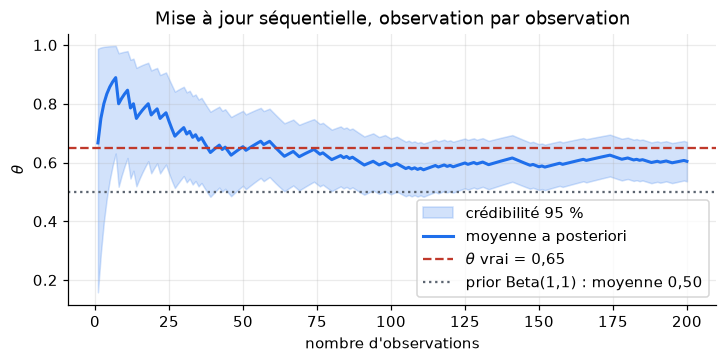

apres  n=5   : Beta(6,1)  moyenne = 0.857
apres  n=20  : Beta(17,5)  moyenne = 0.773
apres  n=200 : Beta(122,80)  moyenne = 0.604
largeur IC 95 % : n=20 -> 0.337   n=200 -> 0.134   rapport observe = 2.51  (theorie sqrt(200/20) = 3.16)


In [7]:
RNG = np.random.default_rng(4112)
obs = (RNG.random(200) < 0.65).astype(int)

# mise a jour lineaire : posterior apres les n premiers lancers
moy, lo, hi = [], [], []
a, b = 1, 1
for i, y in enumerate(obs, start=1):
    a, b = a + y, b + (1 - y)
    d = stats.beta(a, b)
    moy.append(d.mean()); lo.append(d.ppf(.025)); hi.append(d.ppf(.975))

ns = np.arange(1, 201)
plt.figure(figsize=(7.6, 3.2))
plt.fill_between(ns, lo, hi, color="#1F6FEB", alpha=.20, label="crédibilité 95 %")
plt.plot(ns, moy, color="#1F6FEB", lw=2, label="moyenne a posteriori")
plt.axhline(.65, color="#C0392B", ls="--", label=r"$\theta$ vrai = 0,65")
plt.axhline(.50, color="#5B6470", ls=":", label="prior Beta(1,1) : moyenne 0,50")
plt.xlabel("nombre d'observations"); plt.ylabel(r"$\theta$"); plt.legend()
plt.title("Mise à jour séquentielle, observation par observation"); plt.show()

print(f"apres  n=5   : Beta({1+obs[:5].sum()},{1+5-obs[:5].sum()})  moyenne = {moy[4]:.3f}")
print(f"apres  n=20  : Beta({1+obs[:20].sum()},{1+20-obs[:20].sum()})  moyenne = {moy[19]:.3f}")
print(f"apres  n=200 : Beta({1+obs.sum()},{1+200-obs.sum()})  moyenne = {moy[-1]:.3f}")
print(f"largeur IC 95 % : n=20 -> {hi[19]-lo[19]:.3f}   n=200 -> {hi[-1]-lo[-1]:.3f}   "
      f"rapport observe = {(hi[19]-lo[19])/(hi[-1]-lo[-1]):.2f}  (theorie sqrt(200/20) = {np.sqrt(10):.2f})")

In [8]:
# l'ordre des observations change-t-il le posterior final ?
perm = RNG.permutation(obs)
a, b = 1, 1
for y in perm:
    a, b = a + y, b + (1 - y)
print(f"posterior, ordre initial : Beta({1+obs.sum()}, {1+200-obs.sum()})")
print(f"posterior, ordre melange : Beta({a}, {b})")
print("Identiques : la vraisemblance binomiale ne depend que du nombre de succes, pas de l'ordre.")

posterior, ordre initial : Beta(122, 80)
posterior, ordre melange : Beta(122, 80)
Identiques : la vraisemblance binomiale ne depend que du nombre de succes, pas de l'ordre.


---
# 4. Exercice de synthèse — taux de conversion d'un site

Un site observe **37 conversions sur 400 visites**. On veut $p$, le taux de conversion réel.

1. Calculez le posterior avec un prior uniforme, puis avec un prior volontairement **trop optimiste**
   $\mathrm{Beta}(10,2)$ (croyance de départ : 83 % de conversion…).
2. Comparez les deux posteriors : combien d'observations faudrait-il pour que le prior optimiste ne pèse plus ?
3. Donnez la probabilité que le taux dépasse 10 %.

Répondez dans la cellule suivante, puis comparez à la correction.

In [9]:
conv, visites = 37, 400

for nom, (ap, bp) in {"uniforme Beta(1,1)": (1, 1), "optimiste Beta(10,2)": (10, 2)}.items():
    d = stats.beta(ap + conv, bp + visites - conv)
    print(f"{nom:<22} -> Beta({ap+conv},{bp+visites-conv})  moyenne={d.mean():.4f}  "
          f"IC95=[{d.ppf(.025):.4f};{d.ppf(.975):.4f}]  P(p>0,10)={1-d.cdf(.10):.4f}")

print()
print("Le prior optimiste est ecrase : avec 400 visites, la vraisemblance domine completement.")
print("Ordre de grandeur : un prior Beta(10,2) apporte 12 pseudo-observations, soit 3 % des 400 reelles.")

uniforme Beta(1,1)     -> Beta(38,364)  moyenne=0.0945  IC95=[0.0679;0.1249]  P(p>0,10)=0.3393
optimiste Beta(10,2)   -> Beta(47,365)  moyenne=0.1141  IC95=[0.0852;0.1465]  P(p>0,10)=0.8140

Le prior optimiste est ecrase : avec 400 visites, la vraisemblance domine completement.
Ordre de grandeur : un prior Beta(10,2) apporte 12 pseudo-observations, soit 3 % des 400 reelles.


---
# 5. Synthèse

* Posterior conjugué : **Beta-Binomial** — paramètres additionnés, aucune intégrale à calculer.
* Trois méthodes de calcul coïncident : analytique, grille, Monte-Carlo (importance).
* Un prior **s'efface** quand les données arrivent, mais sa vitesse d'effacement dépend de sa masse
  ($\alpha_0+\beta_0$ pseudo-observations).
* L'information croît en $\sqrt{n}$ : doubler la précision exige **quatre fois** plus de données.

**À rendre** : ce notebook exécuté, avec les zones « À vous » complétées
et une phrase de conclusion par section.